# Predicción de enfermedad cardiaca mediante Machine Learning

## Actividad Semana 3 - Operaciones de Aprendizaje Automático

-Axel Fernando Rabago Diaz -A01840541

En este notebook se realizará el flujo básico de un proyecto de Machine Learning utilizando el dataset Heart Failure Prediction Dataset.

El objetivo será analizar y preparar los datos, desarrollar un modelo base de clasificación para predecir la presencia de enfermedad cardiaca y registrar los resultados del experimento mediante MLflow.

A lo largo del ejercicio se documentarán las decisiones tomadas durante las etapas de análisis exploratorio, limpieza, preparación, entrenamiento y evaluación del modelo.

In [61]:
# Librería para trabajar con los datos en forma de tablas
import pandas as pd

# Librería para operaciones numéricas
import numpy as np

# Librerías que utilizaremos posteriormente para generar gráficas
import matplotlib.pyplot as plt

In [62]:
# Cargamos el archivo CSV y lo almacenamos en un DataFrame llamado df
df = pd.read_csv("heart.csv")
# Mostramos los primeros 5 registros del dataset
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [63]:
# Conocer el número de registros y columnas
df.shape

(918, 12)

In [64]:
# Mostrar los nombres de todas las columnas
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [65]:
# Mostrar información general del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


## Descripción del dataset

Para esta actividad se utilizó el dataset **Heart Failure Prediction Dataset** de Kaggle, cuyo objetivo es predecir si un paciente presenta o no enfermedad cardiaca a partir de diferentes variables clínicas.

El conjunto de datos contiene **918 registros y 12 variables**. De estas, **11 corresponden a características del paciente** y la variable **HeartDisease** será nuestra variable objetivo.

El problema es de **clasificación binaria**:

- `0`: no presenta enfermedad cardiaca.
- `1`: presenta enfermedad cardiaca.

### Variables principales

- **Age:** edad del paciente.
- **Sex:** sexo del paciente (`M` o `F`).
- **ChestPainType:** tipo de dolor de pecho.
- **RestingBP:** presión arterial en reposo.
- **Cholesterol:** nivel de colesterol.
- **FastingBS:** glucosa en ayuno mayor a 120 mg/dL.
- **RestingECG:** resultado del electrocardiograma en reposo.
- **MaxHR:** frecuencia cardiaca máxima alcanzada.
- **ExerciseAngina:** presencia de angina durante el ejercicio.
- **Oldpeak:** depresión del segmento ST.
- **ST_Slope:** pendiente del segmento ST.
- **HeartDisease:** presencia o ausencia de enfermedad cardiaca.

El dataset contiene tanto **variables numéricas como categóricas**, por lo que posteriormente será necesario realizar limpieza, transformación y codificación antes de entrenar el modelo.

In [66]:
# Estadísticas descriptivas de las variables numéricas
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### Interpretación de las estadísticas descriptivas

El dataset contiene **918 registros completos** en las variables numéricas mostradas.

La edad promedio de los pacientes es de aproximadamente **53 años**, con edades entre **28 y 77 años**.

La presión arterial en reposo tiene un promedio cercano a **132 mmHg**, aunque se observa un valor mínimo de **0**, lo cual podría representar un dato incorrecto y deberá revisarse durante la etapa de limpieza.

El colesterol promedio es de aproximadamente **199 mg/dL**, con valores que van desde **0 hasta 603 mg/dL**. Los valores iguales a cero también deberán analizarse, ya que podrían representar datos faltantes o registros incorrectos.

La frecuencia cardiaca máxima promedio es de aproximadamente **137 latidos por minuto**, con valores entre **60 y 202**.

La variable `Oldpeak` presenta valores entre **-2.6 y 6.2**, por lo que posteriormente será conveniente revisar su distribución y detectar posibles valores atípicos.

Finalmente, la media de `HeartDisease` es aproximadamente **0.55**, lo que indica que cerca del **55% de los registros corresponden a pacientes con enfermedad cardiaca**.

In [67]:
# Resumen de variables categóricas
df.describe(include='object')

C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\821341470.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


### Interpretación de las variables categóricas

Las variables categóricas también contienen **918 registros**, por lo que inicialmente no se observan valores faltantes en ellas.

La variable `Sex` contiene 2 categorías, siendo `M` la más frecuente.  
`ChestPainType` contiene 4 categorías, donde `ASY` es la más común.  
`RestingECG` tiene 3 categorías y predomina el valor `Normal`.  
`ExerciseAngina` contiene 2 categorías, siendo `N` la más frecuente.  
Finalmente, `ST_Slope` contiene 3 categorías y la categoría más común es `Flat`.

Estas variables deberán transformarse posteriormente a valores numéricos para poder utilizarlas en el modelo de Machine Learning.

In [68]:
# Mostrar la cantidad de registros por categoría
for columna in df.select_dtypes(include='object').columns:
    print(f"\nVariable: {columna}")
    print(df[columna].value_counts())


Variable: Sex
Sex
M    725
F    193
Name: count, dtype: int64

Variable: ChestPainType
ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

Variable: RestingECG
RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

Variable: ExerciseAngina
ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

Variable: ST_Slope
ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64


C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3492581796.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for columna in df.select_dtypes(include='object').columns:


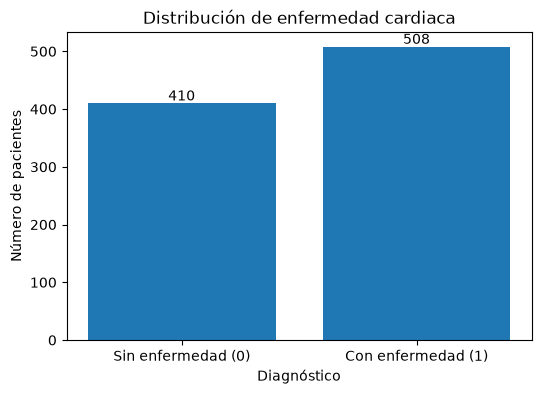

In [69]:
# Contamos los pacientes con y sin enfermedad cardiaca
conteo_heart = df['HeartDisease'].value_counts().sort_index()

# Creamos una gráfica de barras
plt.figure(figsize=(6, 4))
plt.bar(['Sin enfermedad (0)', 'Con enfermedad (1)'], conteo_heart.values)

# Agregamos información a la gráfica
plt.title('Distribución de enfermedad cardiaca')
plt.xlabel('Diagnóstico')
plt.ylabel('Número de pacientes')

# Mostramos el valor encima de cada barra
for i, valor in enumerate(conteo_heart.values):
    plt.text(i, valor + 5, str(valor), ha='center')

plt.show()

In [70]:
# Creamos una tabla cruzada entre sexo y presencia de enfermedad cardiaca
tabla_sexo = pd.crosstab(df['Sex'], df['HeartDisease'])

# Mostramos la tabla
tabla_sexo

HeartDisease,0,1
Sex,,
F,143,50
M,267,458


### Relación entre sexo y enfermedad cardiaca

Al comparar la variable `Sex` con `HeartDisease`, se observa que la mayor parte de los casos positivos se concentra en pacientes masculinos.

Sin embargo, también debe considerarse que el dataset contiene una cantidad mucho mayor de hombres que de mujeres, por lo que esta diferencia no debe interpretarse de manera aislada.

En general, la variable objetivo presenta una distribución suficientemente equilibrada para continuar con el proceso de preparación y modelado.

In [71]:
# Revisamos si existen valores nulos en cada columna
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [72]:
# Revisamos si existen registros duplicados
df.duplicated().sum()

np.int64(0)

In [73]:
# Revisamos cuántos valores iguales a 0 existen en variables donde podrían ser sospechosos
print("RestingBP igual a 0:", (df['RestingBP'] == 0).sum())
print("Cholesterol igual a 0:", (df['Cholesterol'] == 0).sum())

RestingBP igual a 0: 1
Cholesterol igual a 0: 172


### Tratamiento de valores sospechosos

Durante el análisis se encontraron valores iguales a cero en variables clínicas donde este valor puede considerarse incorrecto o representar información no disponible.

- `RestingBP` contiene solamente **1 registro con valor 0**. Debido a que representa una cantidad mínima del dataset y no corresponde a un valor clínicamente razonable, se decidió eliminar dicho registro.
- `Cholesterol` contiene **172 registros con valor 0**, aproximadamente el **18.7% del dataset**. Eliminar todos estos registros ocasionaría una pérdida importante de información, por lo que se decidió sustituir estos valores utilizando la **mediana de los valores válidos de colesterol**.

Se eligió la mediana porque es menos sensible a valores extremos que el promedio.

In [74]:
# Calculamos la mediana del colesterol ignorando los valores iguales a 0
mediana_colesterol = df.loc[df['Cholesterol'] > 0, 'Cholesterol'].median()

print("Mediana de colesterol:", mediana_colesterol)

# Eliminamos el registro donde la presión arterial en reposo es igual a 0
df = df[df['RestingBP'] != 0]

# Sustituimos los valores 0 de colesterol por la mediana calculada
df.loc[df['Cholesterol'] == 0, 'Cholesterol'] = mediana_colesterol

# Verificamos nuevamente
print("RestingBP igual a 0:", (df['RestingBP'] == 0).sum())
print("Cholesterol igual a 0:", (df['Cholesterol'] == 0).sum())
print("Tamaño actual del dataset:", df.shape)

Mediana de colesterol: 237.0
RestingBP igual a 0: 0
Cholesterol igual a 0: 0
Tamaño actual del dataset: (917, 12)


C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3478800087.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[columna], vert=False)


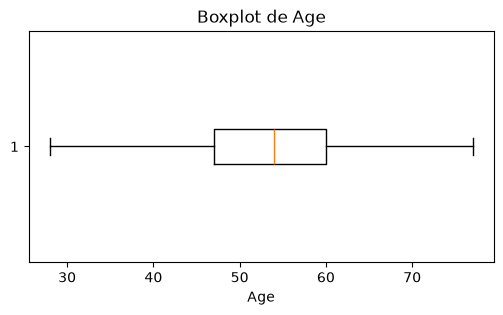

C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3478800087.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[columna], vert=False)


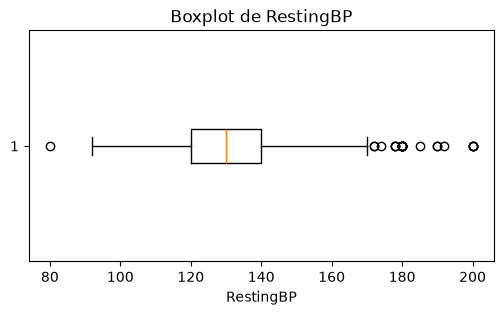

C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3478800087.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[columna], vert=False)


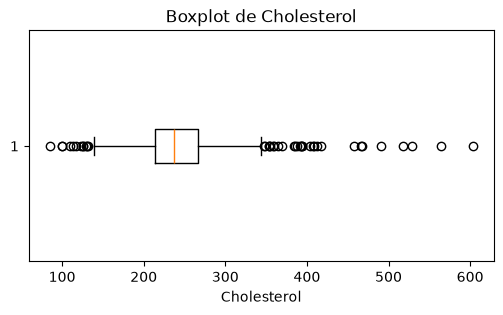

C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3478800087.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[columna], vert=False)


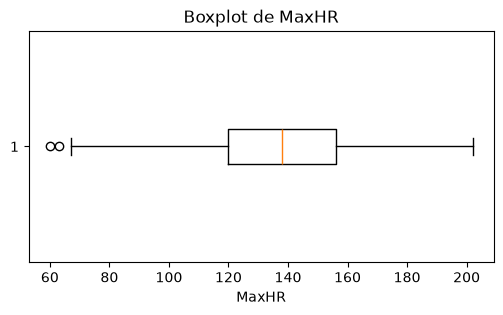

C:\Users\axelr\AppData\Local\Temp\ipykernel_46020\3478800087.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[columna], vert=False)


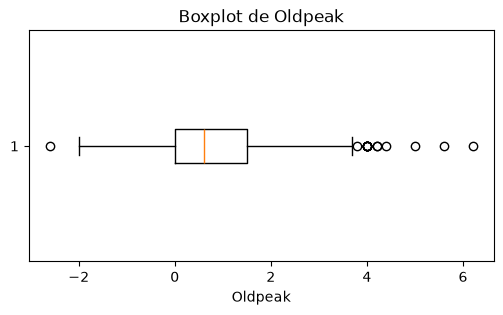

In [75]:
# Variables numéricas que queremos revisar
columnas_numericas = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Creamos un boxplot por variable
for columna in columnas_numericas:
    plt.figure(figsize=(6, 3))
    plt.boxplot(df[columna], vert=False)
    plt.title(f'Boxplot de {columna}')
    plt.xlabel(columna)
    plt.show()

### Revisión de valores atípicos

Mediante diagramas de caja se revisaron posibles valores atípicos en las principales variables numéricas.

Se observaron algunos valores extremos principalmente en `RestingBP`, `Cholesterol`, `MaxHR` y `Oldpeak`. Sin embargo, estos valores se encuentran dentro de rangos posibles del dataset y podrían representar casos reales.

Por esta razón, se decidió **conservar los outliers** y evitar eliminar información que pudiera ser relevante para el entrenamiento del modelo.

In [76]:
# Creamos una copia del dataset limpio para preparar el modelo
df_modelo = df.copy()

# Convertimos las variables binarias a valores 0 y 1
df_modelo['Sex'] = df_modelo['Sex'].map({
    'F': 0,
    'M': 1
})

df_modelo['ExerciseAngina'] = df_modelo['ExerciseAngina'].map({
    'N': 0,
    'Y': 1
})

# Revisamos los primeros registros
df_modelo.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,ATA,140,289,0,Normal,172,0,0.0,Up,0
1,49,0,NAP,160,180,0,Normal,156,0,1.0,Flat,1
2,37,1,ATA,130,283,0,ST,98,0,0.0,Up,0
3,48,0,ASY,138,214,0,Normal,108,1,1.5,Flat,1
4,54,1,NAP,150,195,0,Normal,122,0,0.0,Up,0


In [77]:
# Convertimos las variables categóricas en columnas binarias
df_modelo = pd.get_dummies(
    df_modelo,
    columns=['ChestPainType', 'RestingECG', 'ST_Slope'],
    dtype=int
)

# Revisamos cómo quedó el dataset
df_modelo.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,0,1,0,0,0,1,0,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,0,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,0,0,1,0,0,0,0,1,0,0,1
3,48,0,138,214,0,108,1,1.5,1,1,0,0,0,0,1,0,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,0,1,0,0,1,0,0,0,1


### Transformación de variables categóricas

Las variables binarias `Sex` y `ExerciseAngina` fueron convertidas a valores `0` y `1`.

Las variables `ChestPainType`, `RestingECG` y `ST_Slope` contienen más de dos categorías, por lo que se utilizó **One-Hot Encoding**. Esta técnica permite representar cada categoría mediante una columna independiente sin establecer un orden artificial entre ellas.

Con estas transformaciones, todas las variables quedan representadas numéricamente y pueden ser utilizadas por el modelo de Machine Learning.

In [78]:
df_modelo.shape

(917, 19)

In [79]:
# Calculamos la correlación entre todas las variables
correlacion = df_modelo.corr()

# Mostramos la correlación de cada variable con HeartDisease
correlacion_heart = correlacion['HeartDisease'].sort_values(ascending=False)

correlacion_heart

HeartDisease         1.000000
ST_Slope_Flat        0.553700
ChestPainType_ASY    0.518339
ExerciseAngina       0.495490
Oldpeak              0.403638
Sex                  0.305118
Age                  0.282012
FastingBS            0.267994
ST_Slope_Down        0.122852
RestingBP            0.117990
RestingECG_ST        0.103067
Cholesterol          0.076262
RestingECG_LVH       0.011174
ChestPainType_TA    -0.054591
RestingECG_Normal   -0.092452
ChestPainType_NAP   -0.215311
MaxHR               -0.401410
ChestPainType_ATA   -0.401680
ST_Slope_Up         -0.621843
Name: HeartDisease, dtype: float64

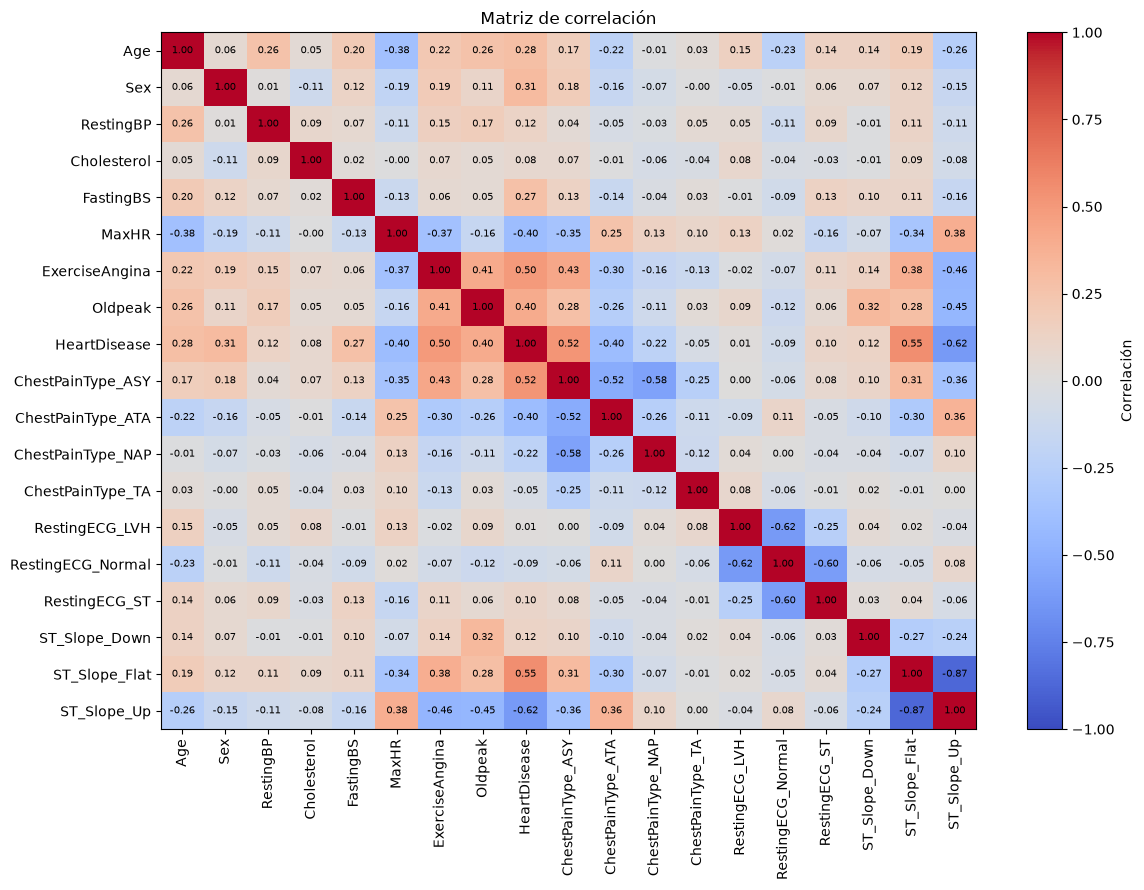

In [80]:
import matplotlib.pyplot as plt

# Matriz de correlación
correlacion = df_modelo.corr()

plt.figure(figsize=(12, 9))

# Creamos el mapa de calor
plt.imshow(correlacion, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)

# Barra lateral de colores
plt.colorbar(label='Correlación')

# Nombres de las variables
plt.xticks(
    range(len(correlacion.columns)),
    correlacion.columns,
    rotation=90
)

plt.yticks(
    range(len(correlacion.columns)),
    correlacion.columns
)

# Agregamos el valor numérico dentro de cada celda
for i in range(len(correlacion.columns)):
    for j in range(len(correlacion.columns)):
        valor = correlacion.iloc[i, j]

        plt.text(
            j,
            i,
            f'{valor:.2f}',
            ha='center',
            va='center',
            fontsize=7
        )

plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

### Análisis de correlación

Se analizó la correlación entre las variables y la presencia de enfermedad cardiaca.

Las variables que muestran una mayor relación con `HeartDisease` son `ST_Slope`, `ChestPainType`, `ExerciseAngina`, `Oldpeak` y `MaxHR`.

También se observa que algunas variables como `Cholesterol`, `RestingBP` y ciertas categorías de `RestingECG` presentan una correlación individual baja.

Sin embargo, se decidió conservar todas las variables para el modelo base, ya que una correlación baja no significa necesariamente que una característica no aporte información cuando se combina con otras variables.

In [81]:
# Variables predictoras
X = df_modelo.drop('HeartDisease', axis=1)

# Variable objetivo
y = df_modelo['HeartDisease']

print("Tamaño de X:", X.shape)
print("Tamaño de y:", y.shape)

Tamaño de X: (917, 18)
Tamaño de y: (917,)


In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (733, 18)
Datos de prueba: (184, 18)


### División de datos

Se separó la variable objetivo `HeartDisease` del resto de las variables predictoras.

Posteriormente, el dataset se dividió en **80% para entrenamiento y 20% para prueba**. También se utilizó una división estratificada para conservar una proporción similar de pacientes con y sin enfermedad cardiaca en ambos conjuntos.

Esta separación permite entrenar el modelo con una parte de los datos y evaluar posteriormente su desempeño utilizando información que no haya visto previamente.

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Creamos un pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(random_state=42))
])

In [84]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Age','Sex','RestingBP',...,'ST_Slope_Down','ST_Slope_Flat','ST_Slope_Up']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [85]:
# Generamos predicciones con los datos de prueba
y_pred = pipeline.predict(X_test)

In [86]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Accuracy: 0.8804
Precision: 0.8922
Recall: 0.8922
F1-score: 0.8922


### Evaluación del modelo base

El modelo de Regresión Logística obtuvo los siguientes resultados:

- **Accuracy:** 0.8804
- **Precision:** 0.8922
- **Recall:** 0.8922
- **F1-score:** 0.8922

Esto indica que el modelo clasifica correctamente aproximadamente el **88% de los casos**.

Además, el valor de `Recall` muestra que el modelo logra identificar cerca del **89% de los pacientes que realmente presentan enfermedad cardiaca**, lo cual es especialmente importante en un problema de salud.

En general, el modelo base presenta un buen desempeño y servirá como referencia para futuras mejoras.

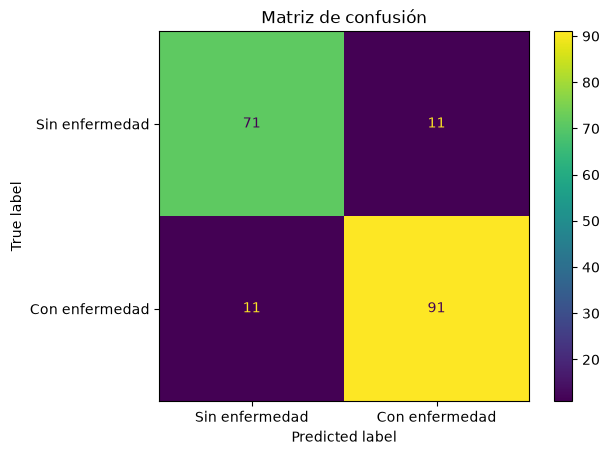

In [87]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculamos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

# La mostramos gráficamente
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Sin enfermedad', 'Con enfermedad']
)

disp.plot()
plt.title('Matriz de confusión')
plt.show()

### Interpretación de la matriz de confusión

La matriz de confusión muestra que el modelo clasificó correctamente a **71 pacientes sin enfermedad cardiaca** y a **91 pacientes con enfermedad cardiaca**.

También se presentaron **11 falsos positivos**, correspondientes a pacientes sanos que fueron clasificados como enfermos, y **11 falsos negativos**, correspondientes a pacientes con enfermedad que el modelo clasificó como sanos.

En general, el modelo presenta un buen desempeño, aunque los falsos negativos son especialmente importantes en un problema de salud, ya que representan casos de enfermedad que podrían no ser detectados.

In [88]:
import mlflow
import mlflow.sklearn
mlflow.set_experiment("Heart_Disease_Prediction")

<Experiment: artifact_location=('file:c:/Users/axelr/OneDrive/Escritorio/Escritorio Dell/Maestria '
 'IA/Operaciones Inteligencia Artificial/Codigos/Proyecto1/mlruns/1'), creation_time=1791173316747, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791173316747, lifecycle_stage='active', name='Heart_Disease_Prediction', tags={}, trace_location=None, workspace='default'>

In [89]:
with mlflow.start_run(run_name="LogisticRegression_Baseline"):

    # Parámetros principales del modelo
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("random_state", 42)
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("scaler", "StandardScaler")

    # Métricas obtenidas
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Guardamos el pipeline completo
    mlflow.sklearn.log_model(
        pipeline,
        "modelo"
    )

2026/10/04 23:01:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


### Registro de la primera iteración en MLflow

Se registró el modelo base como la primera iteración del experimento en MLflow.

En este run se almacenaron los parámetros principales del entrenamiento, las métricas obtenidas y el pipeline completo compuesto por `StandardScaler` y `LogisticRegression`.

Esto permite conservar evidencia del experimento y comparar posteriormente nuevas iteraciones del modelo.

In [90]:
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

mlflow.set_experiment("Heart_Disease_Prediction")

print(
    "Experimento:",
    mlflow.get_experiment_by_name("Heart_Disease_Prediction")
)

Tracking URI: sqlite:///c:/Users/axelr/OneDrive/Escritorio/Escritorio%20Dell/Maestria%20IA/Operaciones%20Inteligencia%20Artificial/Codigos/Proyecto1/mlflow.db
Experimento: <Experiment: artifact_location=('file:c:/Users/axelr/OneDrive/Escritorio/Escritorio Dell/Maestria '
 'IA/Operaciones Inteligencia Artificial/Codigos/Proyecto1/mlruns/1'), creation_time=1791173316747, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791173316747, lifecycle_stage='active', name='Heart_Disease_Prediction', tags={}, trace_location=None, workspace='default'>


### Segunda iteración: Random Forest

Como segunda iteración se utilizó un modelo `RandomForestClassifier` con 100 árboles.

El entrenamiento, predicción, evaluación y registro del experimento se integraron dentro de un mismo flujo. Las métricas obtenidas se almacenaron en MLflow junto con el modelo y la matriz de confusión como artefacto.

Esta segunda iteración permite comparar el desempeño del nuevo modelo contra la Regresión Logística utilizada como baseline.

Accuracy: 0.8804
Precision: 0.8846
Recall: 0.902
F1-score: 0.8932


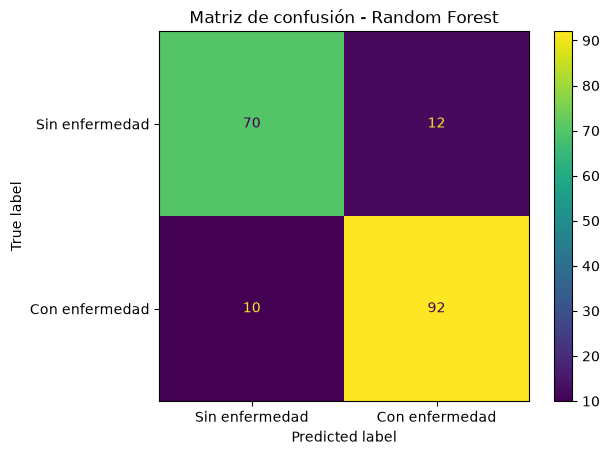

In [91]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn


# ==========================
# 1. Crear Pipeline
# ==========================

pipeline_rf = Pipeline([
    ('modelo', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])


# ==========================
# 2. Entrenar modelo
# ==========================

pipeline_rf.fit(X_train, y_train)


# ==========================
# 3. Generar predicciones
# ==========================

y_pred_rf = pipeline_rf.predict(X_test)


# ==========================
# 4. Calcular métricas
# ==========================

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Accuracy:", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))


# ==========================
# 5. Matriz de confusión
# ==========================

matriz_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=['Sin enfermedad', 'Con enfermedad']
)

disp.plot()
plt.title('Matriz de confusión - Random Forest')

# Guardamos la imagen para MLflow
plt.savefig("matriz_confusion_random_forest.png", bbox_inches='tight')

plt.show()


# ==========================
# 6. Registrar en MLflow
# ==========================

mlflow.set_experiment("Heart_Disease_Prediction")

with mlflow.start_run(run_name="RandomForest_Iteracion_2_Final"):

    # ==========================
    # Parámetros
    # ==========================

    mlflow.log_param("modelo", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("test_size", 0.20)

    # ==========================
    # Métricas
    # ==========================

    mlflow.log_metric("accuracy", accuracy_rf)
    mlflow.log_metric("precision", precision_rf)
    mlflow.log_metric("recall", recall_rf)
    mlflow.log_metric("f1_score", f1_rf)

    # ==========================
    # Guardar modelo
    # ==========================

    mlflow.sklearn.log_model(
        pipeline_rf,
        name="modelo_random_forest",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    # ==========================
    # Guardar matriz de confusión
    # ==========================

    mlflow.log_artifact(
        "matriz_confusion_random_forest.png"
    )


### Segunda iteración: Random Forest

El modelo obtuvo un **Accuracy de 88.04%**, una **Precision de 88.46%**, un **Recall de 90.20%** y un **F1-score de 89.32%**.

En la matriz de confusión se observa que el modelo clasificó correctamente a 70 pacientes sin enfermedad y a 92 pacientes con enfermedad. También presentó 12 falsos positivos y 10 falsos negativos.

Comparado con la Regresión Logística, el desempeño general es muy similar, aunque Random Forest logró un Recall ligeramente mayor, lo que indica que identificó correctamente una mayor proporción de pacientes con enfermedad cardiaca.

Accuracy: 0.8804
Precision: 0.8846
Recall: 0.902
F1-score: 0.8932


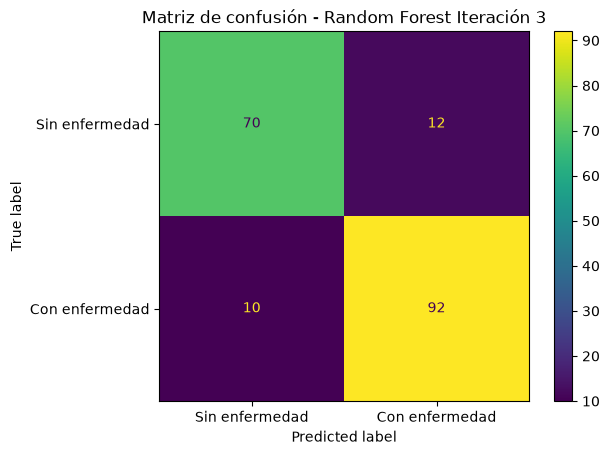

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn


# ==========================
# 1. Crear Pipeline
# ==========================

pipeline_rf3 = Pipeline([
    ('modelo', RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=4,
        random_state=42
    ))
])


# ==========================
# 2. Entrenar modelo
# ==========================

pipeline_rf3.fit(X_train, y_train)


# ==========================
# 3. Generar predicciones
# ==========================

y_pred_rf3 = pipeline_rf3.predict(X_test)


# ==========================
# 4. Calcular métricas
# ==========================

accuracy_rf3 = accuracy_score(y_test, y_pred_rf3)
precision_rf3 = precision_score(y_test, y_pred_rf3)
recall_rf3 = recall_score(y_test, y_pred_rf3)
f1_rf3 = f1_score(y_test, y_pred_rf3)

print("Accuracy:", round(accuracy_rf3, 4))
print("Precision:", round(precision_rf3, 4))
print("Recall:", round(recall_rf3, 4))
print("F1-score:", round(f1_rf3, 4))


# ==========================
# 5. Matriz de confusión
# ==========================

matriz_rf3 = confusion_matrix(y_test, y_pred_rf3)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf3,
    display_labels=['Sin enfermedad', 'Con enfermedad']
)

disp.plot()
plt.title('Matriz de confusión - Random Forest Iteración 3')

# Guardamos la gráfica como artefacto
plt.savefig("matriz_confusion_random_forest_iteracion_3.png", bbox_inches='tight')

plt.show()


# ==========================
# 6. Registrar en MLflow
# ==========================

mlflow.set_experiment("Heart_Disease_Prediction")

with mlflow.start_run(run_name="RandomForest_Iteracion_3"):

    # Parámetros
    mlflow.log_param("modelo", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 8)
    mlflow.log_param("min_samples_split", 4)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("test_size", 0.20)

    # Métricas
    mlflow.log_metric("accuracy", accuracy_rf3)
    mlflow.log_metric("precision", precision_rf3)
    mlflow.log_metric("recall", recall_rf3)
    mlflow.log_metric("f1_score", f1_rf3)

    # Guardamos el modelo
    mlflow.sklearn.log_model(
        pipeline_rf3,
        name="modelo_random_forest_iteracion_3",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    # Guardamos la matriz de confusión
    mlflow.log_artifact(
        "matriz_confusion_random_forest_iteracion_3.png"
    )

### Tercera iteración: ajuste de parámetros de Random Forest

En la tercera iteración se modificaron algunos hiperparámetros del modelo Random Forest:

- `n_estimators = 200`
- `max_depth = 8`
- `min_samples_split = 4`
- `random_state = 42`

El objetivo fue evaluar si una mayor cantidad de árboles y una profundidad controlada mejoraban el desempeño del modelo.

Sin embargo, los resultados fueron prácticamente iguales a los obtenidos en la segunda iteración, con un Accuracy de 88.04%, Precision de 88.46%, Recall de 90.20% y F1-score de 89.32%.

Esto indica que, para este conjunto de datos, los cambios realizados en estos parámetros no generaron una mejora significativa.

# Reflexión final sobre MLOps

Durante esta actividad pude recorrer de manera práctica las principales etapas de un proyecto de Machine Learning, desde el análisis exploratorio y la limpieza de los datos hasta el entrenamiento, evaluación y registro de diferentes modelos. Una de las principales conclusiones que obtuve es que desarrollar un modelo no consiste únicamente en buscar la mejor métrica, sino también en llevar un proceso ordenado, reproducible y fácil de comparar.

El uso de MLflow me permitió entender mejor esta idea, ya que pude registrar diferentes iteraciones, parámetros, métricas y artefactos sin depender únicamente de lo que tenía anotado en el notebook. Por ejemplo, fue posible comparar la Regresión Logística con diferentes configuraciones de Random Forest y comprobar que modificar los parámetros no siempre significa obtener una mejora en el desempeño. Esto también ayuda a evitar trabajar con archivos como “modelo final”, “modelo final 2” o “modelo definitivo”, ya que cada ejecución queda registrada de manera estructurada.

Como mejora al flujo realizado, aplicaría prácticas de MLOps para automatizar todavía más el preprocesamiento, entrenamiento, evaluación y versionamiento de los modelos y datos. También incorporaría validación cruzada, monitoreo del desempeño y mecanismos que permitan detectar cambios en los datos a lo largo del tiempo.

En mi área profesional, estos aprendizajes los relaciono directamente con los sistemas operativos del aeropuerto, donde se generan grandes cantidades de información. Un enfoque MLOps permitiría desarrollar modelos para apoyar predicciones o análisis operativos, pero manteniendo control sobre las versiones, resultados y cambios realizados, algo especialmente importante cuando una solución debe mantenerse de forma confiable en producción.

# Evidencia de mlflow
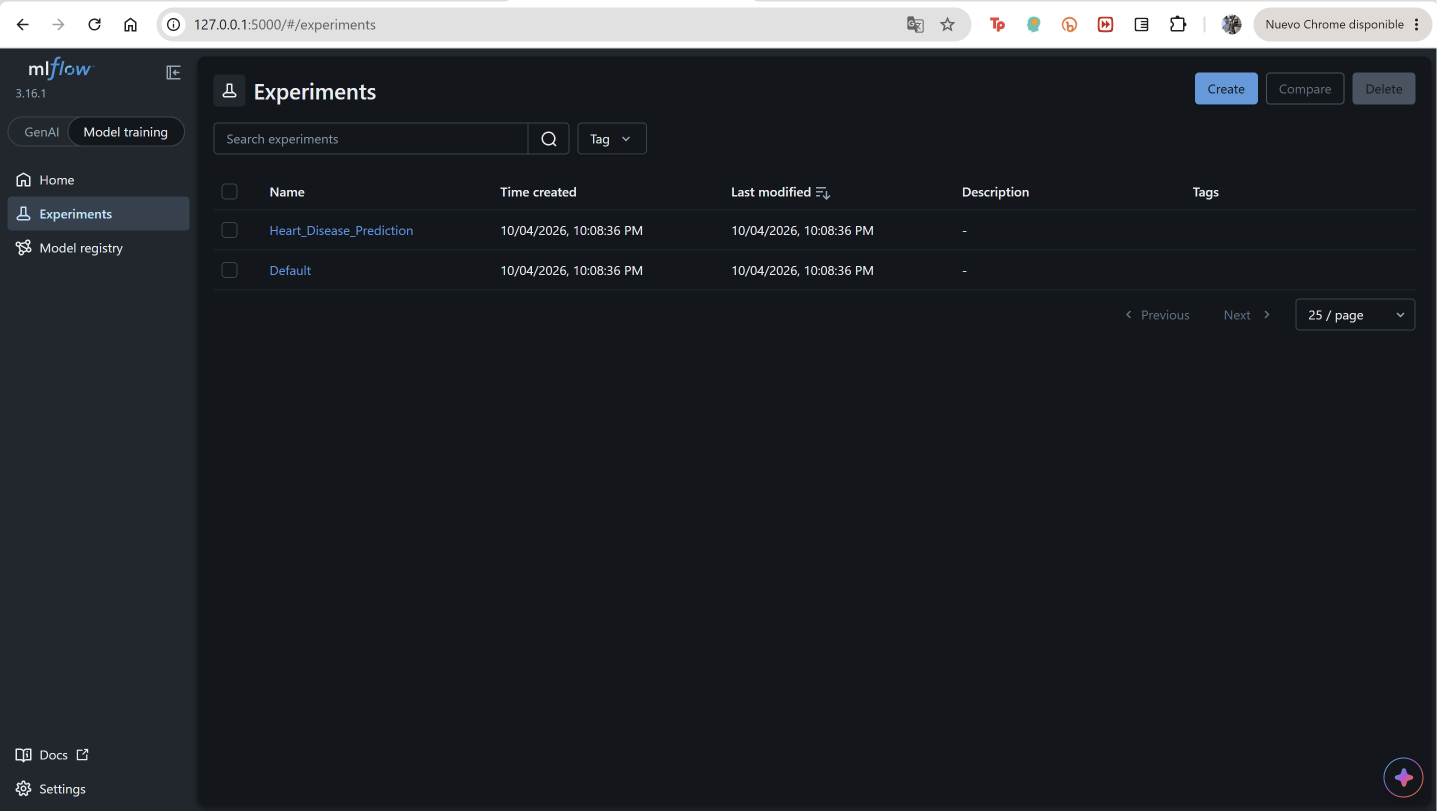
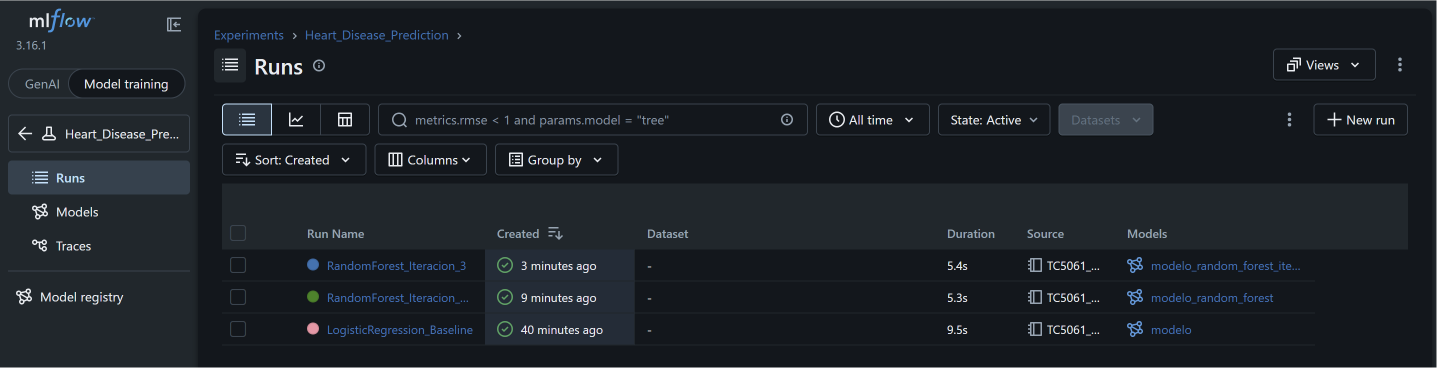
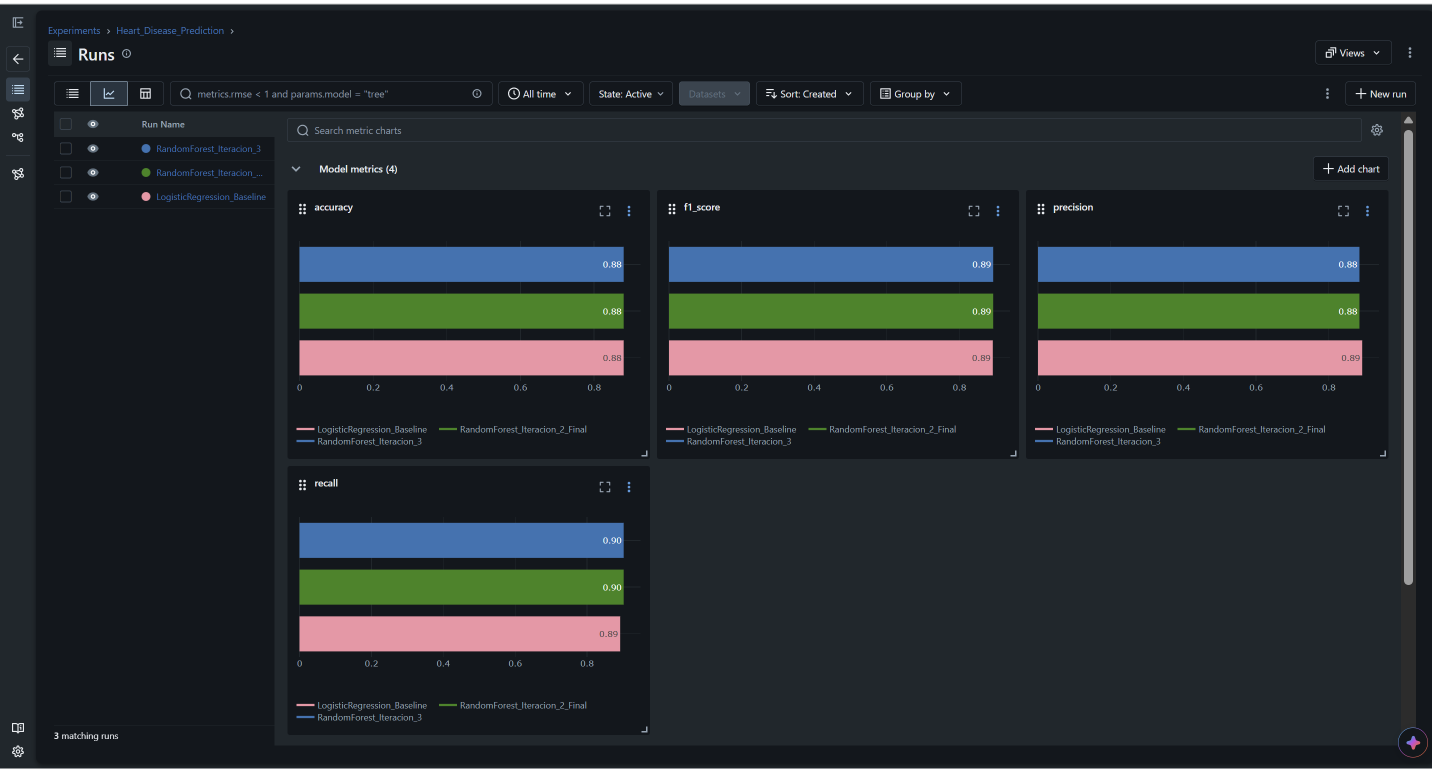
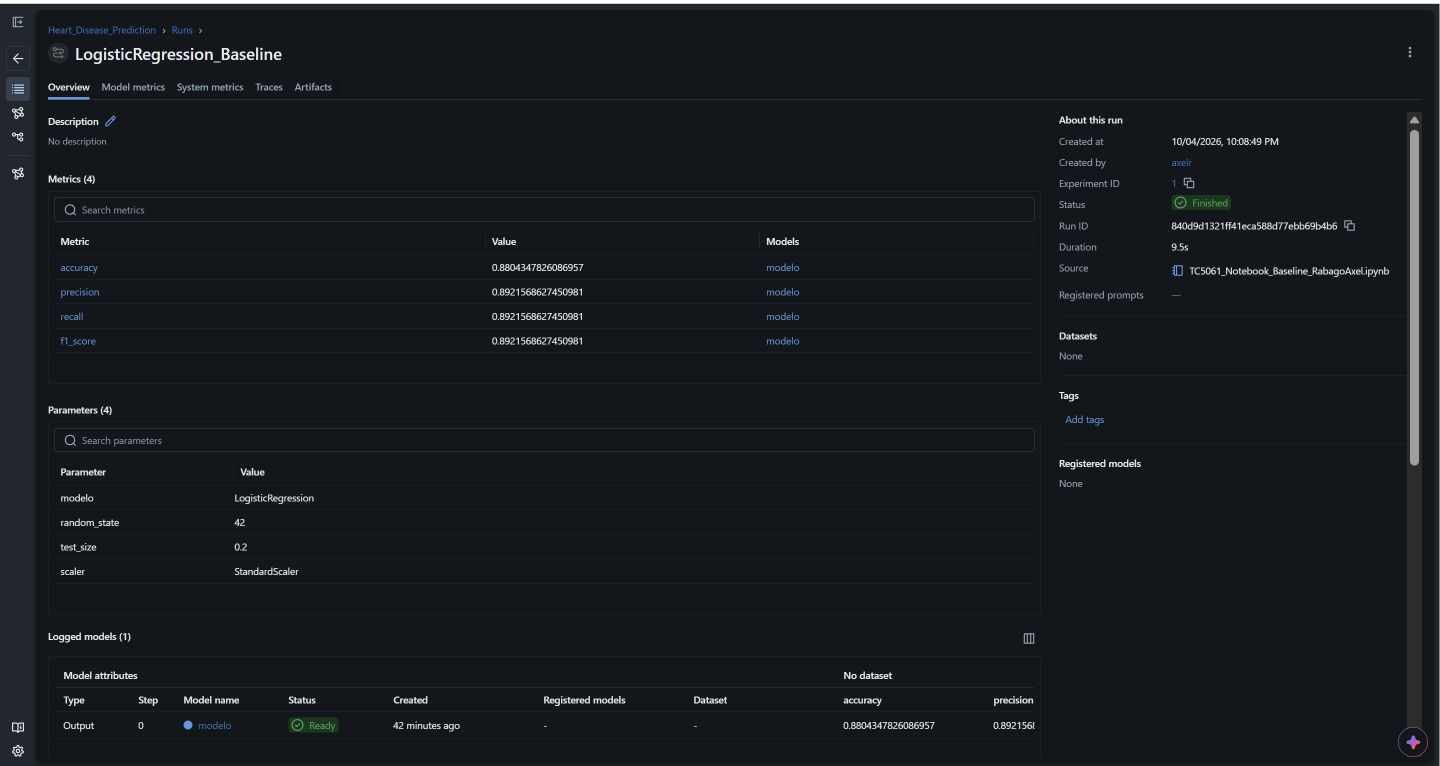
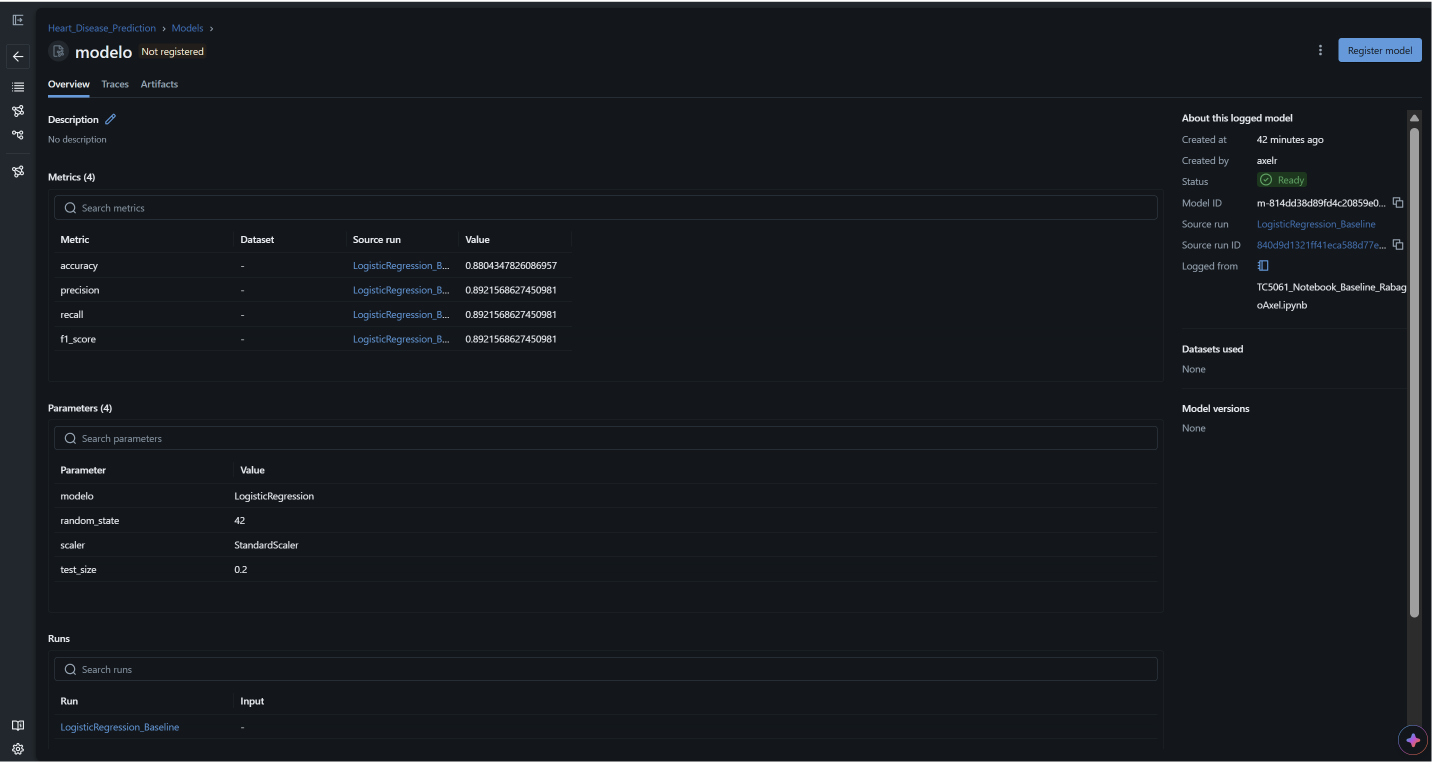
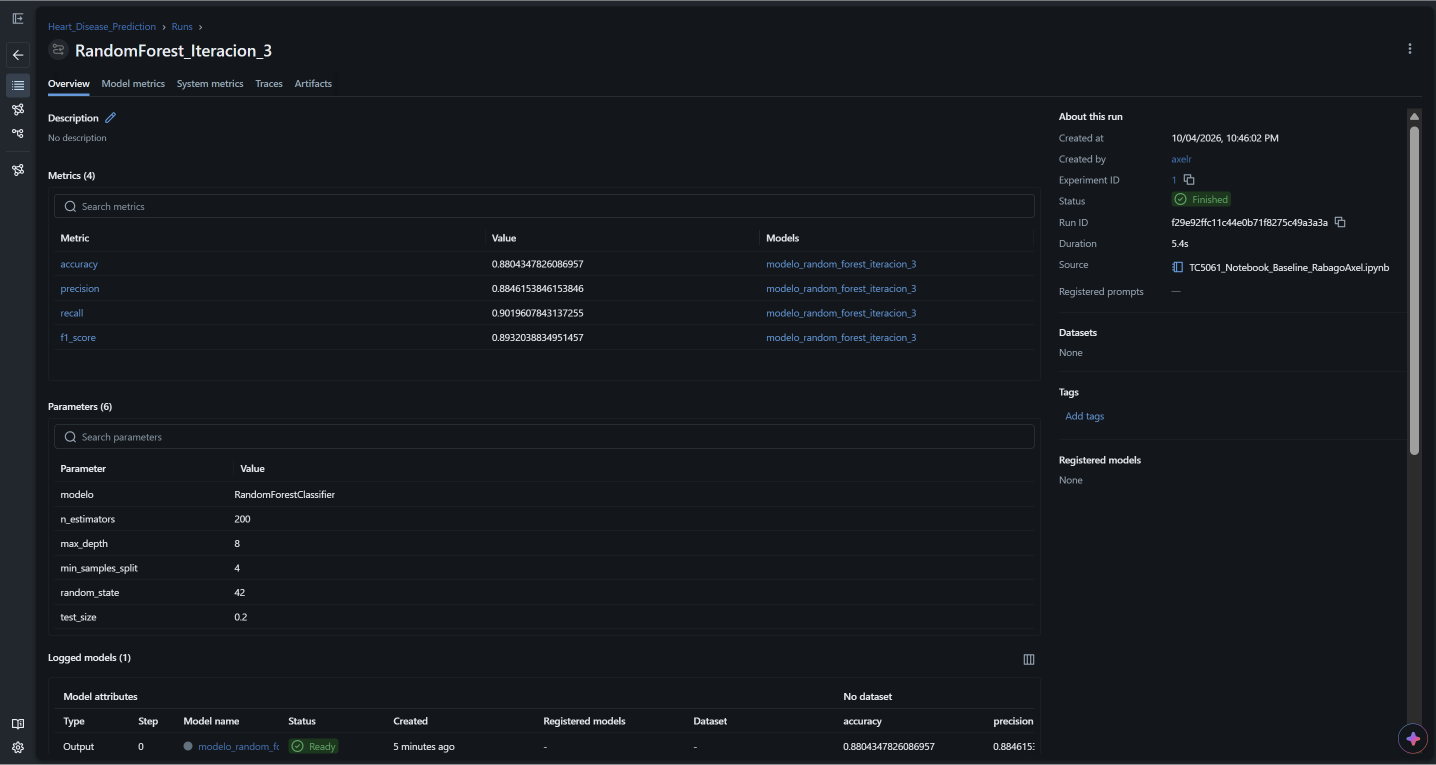
